## Import Libaries

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Insurance Data Load


In [3]:
df = pd.read_csv("insurance.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


## Understanding Data

In [4]:
df.shape

(1338, 7)

In [5]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## Data Preprocessing

In [11]:
df['sex'] = df['sex'].replace({
    'female': 1,
    'male': 0
})
df['smoker'] = df['smoker'].replace({
    'yes': 1,
    'no' : 0
})
    

In [12]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


## EDA

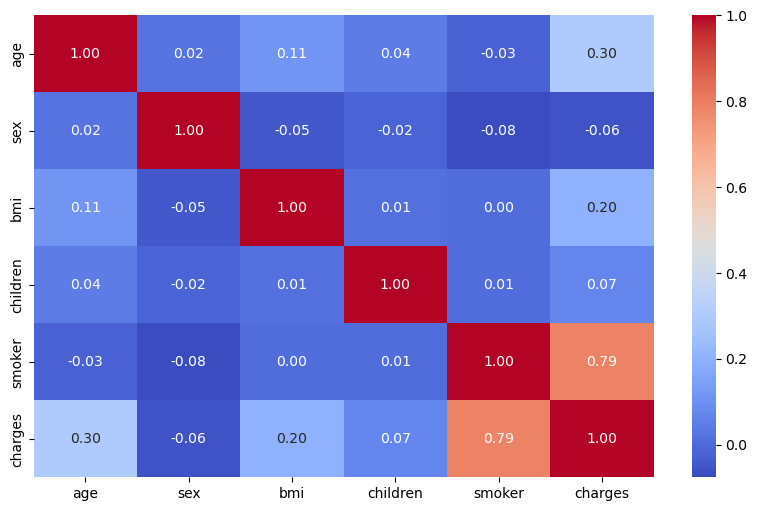

In [15]:
plt.figure(figsize=(10,6))

sns.heatmap(
    df.select_dtypes(include = 'number').corr(),
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f'
)

plt.show()

### Correlation Between Charges and Smoking Status

The heatmap shows a strong positive correlation of **0.79** between smoking status and medical charges. This suggests that smokers tend to have higher medical charges than non-smokers in this dataset. However, correlation does not necessarily mean causation.

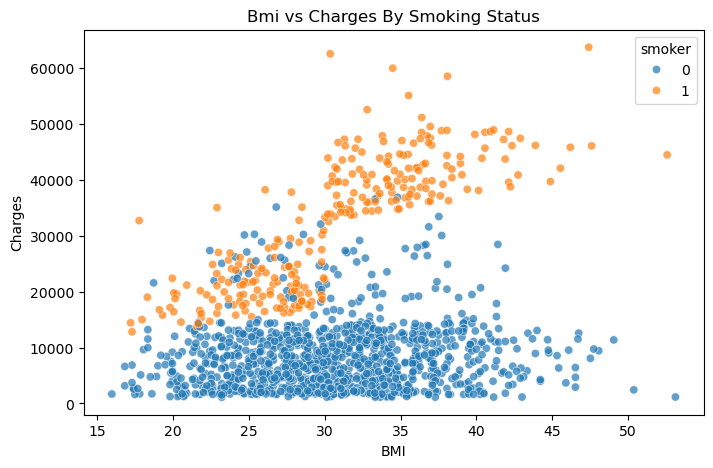

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data = df,
    x = 'bmi',
    y = 'charges',
    hue = 'smoker',
    alpha = 0.7
)

plt.title("Bmi vs Charges By Smoking Status")
plt.xlabel("BMI")
plt.ylabel("Charges")

plt.show()

## Feature Engineering

In [25]:
df_enc = pd.get_dummies(df,columns =['region'],dtype = int)

In [26]:
df_enc.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,0,1
1,18,0,33.770,1,0,1725.55230,0,0,1,0
2,28,0,33.000,3,0,4449.46200,0,0,1,0
3,33,0,22.705,0,0,21984.47061,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0


## Train Test Split

In [31]:
X = df_enc.drop(columns=['charges'], axis = 1)
y = df_enc['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state = 42)

In [32]:
#Scaling Data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [38]:
#Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [39]:
y_pred = model.predict(X_test)

## Evaluation 

In [42]:
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.7696118054369009
MAE: 4145.450555627592
RMSE: 5812.100272258874


### Model Evaluation and Conclusion

I trained a **Linear Regression model** to predict medical insurance charges using features such as age, sex, BMI, children, smoking status, and region.

**Evaluation Metrics:**
- **R² Score:** 0.77
- **MAE:** 4,145.45
- **RMSE:** 5,812.10

The model explains approximately **77% of the variation** in medical insurance charges. On average, its predictions differ from actual charges by around 4,145.45 units.

**Conclusion:** The model shows a reasonable predictive performance. Further improvements could be explored through feature engineering, outlier analysis, and comparison with other regression algorithms.